# Taller 08: Random Forest para reconocer dígitos
**Inteligencia Artificial - ELP 8012 - Universidad del Norte**  
**Profesor:** Eduardo Zurek, Ph.D.  
**Grupo 15** Galvis Pajaro, Carlos · Molina Vega, Dayana · Romero Pemberthy, Juan

## Qué pedía el enunciado y cómo lo resolvemos
El objetivo es armar un Random Forest con el dataset `digits` de sklearn y encontrar un modelo que use **pocos árboles**, que esos árboles sean **lo más pequeños posible** y que el rendimiento se mantenga bien **sin sobreajustar**. Esos tres pedidos a veces se pelean entre sí: el bosque con la mejor nota no siempre es el más chico. Por eso, antes de mirar resultados, dejamos escrita una regla clara de compromiso.

| Lo que pide el taller | Dónde lo hacemos aquí |
|---|---|
| Dataset `digits` de sklearn | Sección 2: 1.797 imágenes, diez dígitos, 64 píxeles |
| División 80/20 | Sección 2: separación estratificada |
| K-fold = 4 | Sección 3: cuatro folds solo con el entrenamiento |
| Mínimo número de árboles | Secciones 4 a 6: probamos todos los enteros de 1 a 100 |
| Árboles lo más pequeños posible | Contamos nodos, hojas y profundidad reales |
| Control del sobreajuste | Miramos la brecha entrenamiento-validación, regularizamos y dejamos la prueba aparte |
| Explicar la poda o el freno del crecimiento | Secciones 1 y 8: `ccp_alpha`, `max_depth` y `min_samples_leaf` |
| Código Python y Markdown | Todo va en este mismo cuaderno |

**Hasta dónde llega el resultado:** encontramos el mínimo bajo una regla y una rejilla concretas. Eso no prueba un mínimo universal para cualquier otra configuración, ni que el sobreajuste haya desaparecido del todo.


## 1. Método: clasificación, complejidad y poda
Cada árbol va partiendo los datos con preguntas sobre píxeles. Por ejemplo: «¿el píxel 35 tiene intensidad menor que cierto umbral?». Al final, en las hojas queda una distribución de clases (qué dígitos caen ahí). El Random Forest arma muchos de esos árboles, cada uno con una muestra bootstrap distinta y con un subconjunto aleatorio de variables. En scikit-learn, la predicción final mira el **promedio de las probabilidades** de todos los árboles y se queda con la clase que tenga más probabilidad.

No estandarizamos los píxeles. Los árboles trabajan con umbrales, no con distancias euclidianas, así que dejamos los 64 atributos originales con su rango de 0 a 16.

### Cómo limitamos el tamaño de cada árbol
| Parámetro | Qué tipo de control es | Qué hace en la práctica |
|---|---|---|
| `max_depth` | Frena el crecimiento | No deja que el árbol se profundice más allá de un límite |
| `min_samples_leaf` | Frena el crecimiento | Evita hojas con demasiado pocos ejemplos |
| `ccp_alpha` | Poda después de crecer | Recorta subárboles cuya mejora de impureza no vale la pena frente a su complejidad |
| `n_estimators` | Tamaño del bosque | Cambia cuántos árboles hay; no poda cada árbol por dentro |

La idea de la poda por costo-complejidad (la misma del cuaderno del profesor sobre `ccp_alpha`) se resume así:

$$R_\alpha(T)=R(T)+\alpha\,|T_L|.$$

Aquí $R(T)$ es la impureza total de las hojas, $|T_L|$ es cuántas hojas tiene el árbol y $\alpha$ es `ccp_alpha`. Si subes alpha, penalizas más el hecho de tener muchas hojas, y el árbol queda más chico. Con `ccp_alpha=0` no hay esa poda extra, aunque `max_depth` o `min_samples_leaf` igual pueden frenar el crecimiento. Si podas de más, el modelo se queda corto (**subajuste**).

En un Random Forest, el alpha se aplica cada árbol por separado. La ruta de poda de un solo árbol no habla automáticamente por todo el bosque. Por eso aquí usamos una rejilla fija de alphas (sin mirar las etiquetas de validación para inventarlos) y medimos el efecto sobre el bosque completo.

Más árboles suelen estabilizar el promedio, pero no garantizan que cada árbol nuevo mejore el resultado. Y un 100 % en entrenamiento tampoco garantiza buen desempeño en datos nuevos.


## 2. Configuración, datos y división 80/20
En Colab ya suelen estar las librerías que usamos. Si corres esto en tu computador, necesitas `numpy`, `pandas`, `matplotlib`, `scikit-learn` e `IPython`. La celda imprime las versiones para que la corrida sea reproducible. Semilla fija: 42.


In [ ]:
import sys, time, itertools
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEMILLA = 42
MAX_ARBOLES = 100
PROFUNDIDADES = [8, 12, None]
MIN_HOJAS = [1, 2]
ALPHAS = [0.0, 0.001, 0.003, 0.006]
TOLERANCIA_F1 = 0.005        # Hasta 0,5 puntos porcentuales bajo el mejor F1 medio.
BRECHA_MAXIMA = 0.03        # Hasta 3 puntos porcentuales de brecha media de F1.
CLASES = np.arange(10)
METRICAS = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
AZUL, OCRE, ROSA = '#205C90', '#B46918', '#9B4F79'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 15)
pd.set_option('display.precision', 5)
print(f'Python {sys.version.split()[0]} | sklearn {sklearn.__version__} | '
      f'NumPy {np.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}')

digits = load_digits()
X, y = digits.data.astype(np.float32), digits.target.astype(int)
assert X.shape == (1797, 64) and np.isfinite(X).all()
assert X.min() >= 0 and X.max() <= 16
assert np.array_equal(np.unique(y), CLASES)
idx_train, idx_test = train_test_split(np.arange(len(y)), test_size=0.20,
                                     random_state=SEMILLA, stratify=y)
X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y[idx_train], y[idx_test]
assert set(idx_train).isdisjoint(idx_test)
assert len(idx_train) + len(idx_test) == len(y)
print(f'Entrenamiento: {len(y_train)} ({len(y_train)/len(y):.2%})')
print(f'Prueba reservada: {len(y_test)} ({len(y_test)/len(y):.2%})')
print('Filas de píxeles duplicadas en el dataset:', len(X)-len(np.unique(X, axis=0)))
display(pd.DataFrame({'Dígito':CLASES, 'Entrenamiento':np.bincount(y_train),
                      'Prueba':np.bincount(y_test)}))

Python 3.14.6 | sklearn 1.9.0 | NumPy 2.4.6 | pandas 3.0.3 | matplotlib 3.11.1
Entrenamiento: 1437 (79.97%)
Prueba reservada: 360 (20.03%)
Filas de píxeles duplicadas en el dataset: 0


,Dígito,Entrenamiento,Prueba
0,0,142,36
1,1,146,36
2,2,142,35
3,3,146,37
4,4,145,36
5,5,145,37
6,6,145,36
7,7,143,36
8,8,139,35
9,9,144,36


La división deja **1.437 imágenes para entrenar y 360 para probar**. No es exactamente 80/20 al milímetro porque no se pueden partir medias imágenes; el redondeo hace esa diferencia mínima. Abajo solo mostramos ejemplos del entrenamiento. La prueba se guarda intacta hasta la sección 9.


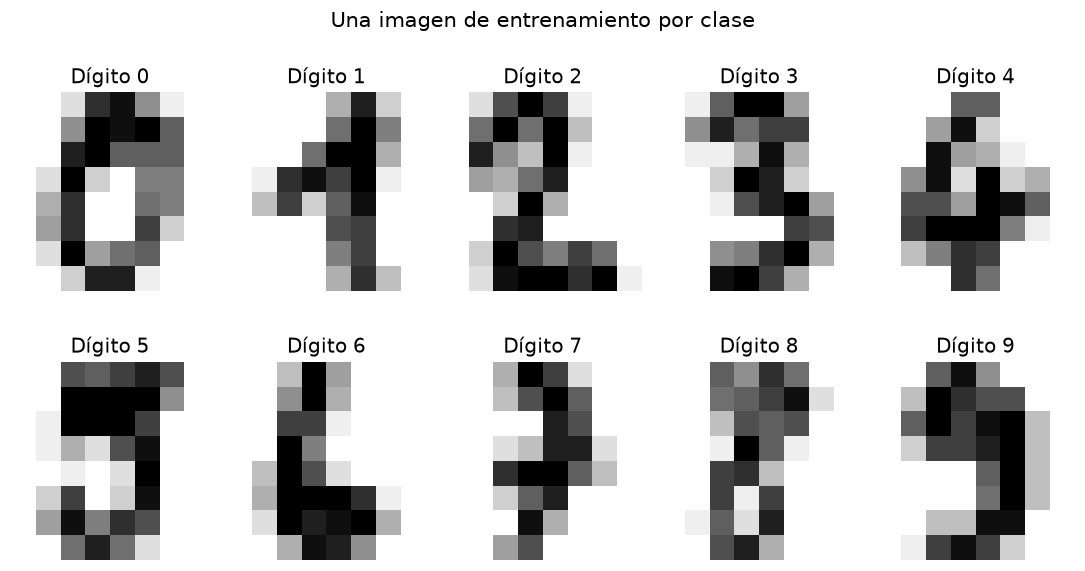

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5.6))
for c, ax in zip(CLASES, axes.ravel()):
    i = np.flatnonzero(y_train == c)[0]
    ax.imshow(X_train[i].reshape(8, 8), cmap='gray_r', vmin=0, vmax=16)
    ax.set_title(f'Dígito {c}')
    ax.axis('off')
fig.suptitle('Una imagen de entrenamiento por clase', fontsize=14)
fig.tight_layout(h_pad=2.5)
plt.show()

## 3. K-fold = 4 y métricas
Usamos `StratifiedKFold(n_splits=4)` para que cada fold conserve, más o menos, la misma proporción de cada dígito. En cada ronda entrenamos con tres partes y validamos con la cuarta. Así, cada imagen de entrenamiento pasa exactamente una vez por validación. Las mismas particiones se reutilizan para todas las configuraciones, y así comparamos en igualdad de condiciones.

- **Exactitud:** aciertos sobre el total de imágenes.
- **Precisión macro:** promedio de la precisión de cada dígito.
- **Recall macro:** promedio de cuántos ejemplos de cada dígito recuperamos bien.
- **F1 macro:** promedio de los diez F1 por clase. Equilibra precisión y recall, y trata cada dígito por igual (aunque haya un poco más o menos de alguno).
- **Brecha de F1:** F1 de entrenamiento menos F1 de validación. Si esa diferencia es grande y positiva, es una señal de posible sobreajuste, no una prueba definitiva.

Las medias de validación pesan igual a los cuatro folds. La desviación estándar entre folds muestra cuánto varía el resultado; no la estamos usando como intervalo de confianza.


In [ ]:
folds = list(StratifiedKFold(n_splits=4, shuffle=True, random_state=SEMILLA)
             .split(X_train, y_train))
conteo = np.zeros(len(y_train), dtype=int)
filas = []
for fold, (a, v) in enumerate(folds, 1):
    assert set(a).isdisjoint(v)
    assert len(np.unique(y_train[a])) == len(np.unique(y_train[v])) == 10
    conteo[v] += 1
    filas.append({'Fold':fold, 'Ajuste':len(a), 'Validación':len(v)})
assert np.all(conteo == 1)
display(pd.DataFrame(filas))

,Fold,Ajuste,Validación
0,1,1077,360
1,2,1078,359
2,3,1078,359
3,4,1078,359


## 4. Espacio de búsqueda y regla de selección
Probamos **todos los números de árboles de 1 a 100**, cruzados con 24 perfiles estructurales: 3 límites de profundidad × 2 mínimos de muestras por hoja × 4 valores de alpha. En total son **2.400 candidatos**, y cada uno se mide en los cuatro folds.

La regla se escribe **antes** de lanzar la búsqueda:

1. Buscamos el máximo F1 macro medio de validación entre todos los candidatos.
2. Aceptamos como «casi tan bueno» cualquier modelo cuyo F1 no baje más de **0,005** respecto a ese máximo, y cuya brecha media entrenamiento-validación de F1 sea de **como máximo 0,03**.
3. Entre los que pasan, preferimos primero el **menor número de árboles** y, a igualdad de árboles, el menor **número medio real de nodos por árbol**.
4. Si todavía hay empate, nos quedamos con la menor profundidad media real y, después, con el mejor F1 y exactitud de validación.

Esas tolerancias son una decisión de diseño del taller, no una ley universal. No las vamos a retocar mirando la prueba. Si nadie cumple los criterios, el código se detiene en vez de inventar que ya cumplimos el objetivo.

**Prioridad clara:** primero minimizamos la cantidad de árboles (eso es lo que pide el enunciado de forma más directa). Un bosque con más árboles podría tener, aun así, menos nodos totales; por eso también calculamos esa alternativa, para ver el compromiso. Y reportamos el ganador estricto de F1, para que se note qué estamos dejando sobre la mesa.


In [ ]:
perfiles = [dict(max_depth=d, min_samples_leaf=l, ccp_alpha=a)
            for d, l, a in itertools.product(PROFUNDIDADES, MIN_HOJAS, ALPHAS)]
def crear_bosque(n, perfil):
    return RandomForestClassifier(
        n_estimators=int(n), criterion='gini', max_features='sqrt',
        bootstrap=True, random_state=SEMILLA, n_jobs=1,
        min_samples_split=2, **perfil)

print('Perfiles:',len(perfiles),'| Candidatos:',len(perfiles)*MAX_ARBOLES,
      '| Evaluaciones en folds:',len(perfiles)*MAX_ARBOLES*len(folds))
display(pd.DataFrame(perfiles).fillna('Sin límite'))

Perfiles: 24 | Candidatos: 2400 | Evaluaciones en folds: 9600


,max_depth,min_samples_leaf,ccp_alpha
0,8.0,1,0.000
1,8.0,1,0.001
2,8.0,1,0.003
3,8.0,1,0.006
4,8.0,2,0.000
5,8.0,2,0.001
6,8.0,2,0.003
7,8.0,2,0.006
8,12.0,1,0.000
9,12.0,1,0.001


### 4.1. Cómo evaluamos todos los tamaños sin entrenar 100 bosques desde cero
Para un perfil y un fold entrenamos un solo bosque de 100 árboles y después evaluamos sus primeros 1, 2, ..., 100 árboles. Con los mismos parámetros y la misma semilla, cada árbol se construye de forma independiente de los que vienen después. Así reutilizamos trabajo y no repetimos 100 entrenamientos completos.

Para cada tamaño $n$, sumamos las probabilidades de esos $n$ árboles y elegimos la clase con mayor suma. Es lo mismo que tomar el promedio y quedarnos con el máximo:

$$\hat y=\arg\max_c\;\frac{1}{n}\sum_{t=1}^{n}p_t(c\mid x).$$

Eso respeta la forma en que predice Random Forest en scikit-learn; no lo cambiamos por una votación de etiquetas duras. Al final comprobamos que el prefijo elegido coincida, en los cuatro folds, con un `RandomForestClassifier` entrenado directamente con ese número de árboles.

Las métricas rápidas salen de una matriz de confusión para no demorar las miles de evaluaciones, y las contrastamos con las funciones oficiales de scikit-learn.


In [ ]:
def metricas_rapidas(reales, predichas):
    # Filas = clase real, columnas = clase predicha; etiquetas 0,...,9.
    cm = np.bincount(10*reales + predichas, minlength=100).reshape(10, 10)
    tp = np.diag(cm).astype(float)
    soporte = cm.sum(axis=1)
    pred_totales = cm.sum(axis=0)
    precision = np.divide(tp, pred_totales, out=np.zeros(10), where=pred_totales != 0)
    recall = np.divide(tp, soporte, out=np.zeros(10), where=soporte != 0)
    f1 = np.divide(2*tp, soporte+pred_totales, out=np.zeros(10), where=(soporte+pred_totales) != 0)
    return dict(accuracy=tp.sum()/cm.sum(), precision_macro=precision.mean(),
                recall_macro=recall.mean(), f1_macro=f1.mean())

def metricas_sklearn(reales, predichas):
    return dict(accuracy=accuracy_score(reales,predichas),
        precision_macro=precision_score(reales,predichas,labels=CLASES,average='macro',zero_division=0),
        recall_macro=recall_score(reales,predichas,labels=CLASES,average='macro',zero_division=0),
        f1_macro=f1_score(reales,predichas,labels=CLASES,average='macro',zero_division=0))

# Caso con algunas clases sin predicciones para verificar denominadores cero.
y_control = np.arange(10).repeat(3)
p_control = (y_control // 2).astype(int)
assert np.allclose(list(metricas_rapidas(y_control,p_control).values()),
                   list(metricas_sklearn(y_control,p_control).values()))

## 5. Ejecutar la validación cruzada
Esta es la celda más pesada. Entrena 96 bosques de 100 árboles (24 perfiles × 4 folds) y evalúa 9.600 prefijos en total. Cada prefijo es un candidato con distinto número de árboles dentro de un fold. Los datos de prueba **no entran** en esta función.

Para medir tamaño, de cada árbol sacamos su cantidad real de nodos, de hojas y su profundidad. Contar solo el número de árboles no alcanza para describir toda la complejidad.


In [ ]:
def buscar_bosques(datos, etiquetas, particiones, perfiles, max_arboles):
    registros = []
    for perfil_id, perfil in enumerate(perfiles):
        for fold, (a, v) in enumerate(particiones, 1):
            bosque = crear_bosque(max_arboles, perfil)
            bosque.fit(datos[a], etiquetas[a])
            suma_a = np.zeros((len(a), 10)); suma_v = np.zeros((len(v), 10))
            nodos = hojas = profundidad = 0
            for n, arbol in enumerate(bosque.estimators_, 1):
                suma_a += arbol.predict_proba(datos[a])
                suma_v += arbol.predict_proba(datos[v])
                pred_a = bosque.classes_[np.argmax(suma_a, axis=1)]
                pred_v = bosque.classes_[np.argmax(suma_v, axis=1)]
                ma = metricas_rapidas(etiquetas[a], pred_a)
                mv = metricas_rapidas(etiquetas[v], pred_v)
                nodos += arbol.tree_.node_count
                hojas += arbol.get_n_leaves()
                profundidad += arbol.get_depth()
                registros.append(dict(perfil_id=perfil_id, fold=fold, n_estimators=n,
                    **{'train_'+k:valor for k,valor in ma.items()},
                    **{'val_'+k:valor for k,valor in mv.items()},
                    gap_f1=ma['f1_macro']-mv['f1_macro'],
                    nodos_medios=nodos/n, hojas_medias=hojas/n,
                    profundidad_media=profundidad/n, nodos_totales=nodos))
            assert np.allclose(suma_v/max_arboles, bosque.predict_proba(datos[v]))
            assert np.allclose(list(mv.values()),list(metricas_sklearn(etiquetas[v],pred_v).values()))
        if (perfil_id+1) % 6 == 0:
            print(f'Perfiles completados: {perfil_id+1}/{len(perfiles)}')
    return pd.DataFrame(registros)

inicio = time.perf_counter()
resultados_folds = buscar_bosques(X_train,y_train,folds,perfiles,MAX_ARBOLES)
print(f'Tiempo de búsqueda en este equipo: {time.perf_counter()-inicio:.1f} segundos')
grupos = resultados_folds.groupby(['perfil_id','n_estimators'],sort=True)
columnas_medias = [c for c in resultados_folds.columns if c not in ['perfil_id','n_estimators','fold']]
resumen = grupos[columnas_medias].mean().reset_index()
resumen['val_f1_std'] = grupos['val_f1_macro'].std(ddof=1).to_numpy()
resumen['val_accuracy_std'] = grupos['val_accuracy'].std(ddof=1).to_numpy()
assert len(resumen) == len(perfiles)*MAX_ARBOLES
assert (grupos.size() == 4).all()
assert np.isfinite(resumen.to_numpy()).all()
print('Candidatos evaluados:',len(resumen))

## 6. Elegir el bosque más sencillo que conserve el rendimiento
Guardamos tres referencias: el máximo F1 de validación, la selección principal (mínimo número de árboles) y una alternativa que minimiza el total de nodos. La prueba sigue sin tocarse. Ojo: los tamaños que ves aquí son promedios de los cuatro ajustes de validación; cuando reajustemos con todas las imágenes de entrenamiento, el tamaño final puede moverse un poco.


In [ ]:
mejor_f1 = resumen.sort_values(['val_f1_macro','val_accuracy','n_estimators','nodos_medios'],
                              ascending=[False,False,True,True]).iloc[0]
umbral_f1 = float(mejor_f1['val_f1_macro']-TOLERANCIA_F1)
resumen['elegible'] = ((resumen.val_f1_macro >= umbral_f1-1e-12) &
                       (resumen.gap_f1 <= BRECHA_MAXIMA+1e-12))
elegibles = resumen[resumen.elegible].copy()
if elegibles.empty:
    raise ValueError('No hay candidato que cumpla los criterios fijados. No declarar ausencia de sobreajuste.')
elegido = elegibles.sort_values(
    ['n_estimators','nodos_medios','profundidad_media','val_f1_macro','val_accuracy','perfil_id'],
    ascending=[True,True,True,False,False,True]).iloc[0]
alternativa_nodos = elegibles.sort_values(['nodos_totales','n_estimators','val_f1_macro'],
                                        ascending=[True,True,False]).iloc[0]
N_ELEGIDO = int(elegido.n_estimators)
PERFIL_ELEGIDO = perfiles[int(elegido.perfil_id)].copy()
assert not elegibles[elegibles.n_estimators < N_ELEGIDO].shape[0]
assert elegido.nodos_medios == elegibles[elegibles.n_estimators == N_ELEGIDO].nodos_medios.min()

def describir(fila,nombre):
    perfil = perfiles[int(fila.perfil_id)]
    return {'Criterio':nombre,'Árboles':int(fila.n_estimators),
            'max_depth':str(perfil['max_depth']), 'min_samples_leaf':perfil['min_samples_leaf'],
            'ccp_alpha':perfil['ccp_alpha'], 'F1 CV':fila.val_f1_macro,
            'Exactitud CV':fila.val_accuracy,'Brecha F1':fila.gap_f1,
            'Nodos/árbol CV':fila.nodos_medios,'Nodos totales CV':fila.nodos_totales}
comparacion_cv = pd.DataFrame([describir(mejor_f1,'Máximo F1'),
                               describir(elegido,'Selección principal'),
                               describir(alternativa_nodos,'Mínimo total de nodos')])
display(comparacion_cv)
print('Umbral de F1 para elegibilidad:',round(umbral_f1,6))
print('Candidatos elegibles:',len(elegibles))
print('Parámetros elegidos:',dict(n_estimators=N_ELEGIDO,**PERFIL_ELEGIDO))
display(elegibles.sort_values(['n_estimators','nodos_medios']).head(10)[
    ['perfil_id','n_estimators','val_f1_macro','val_accuracy','gap_f1','nodos_medios','profundidad_media']])

Umbral de F1 para elegibilidad: 0.971848
Candidatos elegibles: 211
Parámetros elegidos: {'n_estimators': 30, 'max_depth': None, 'min_samples_leaf': 2, 'ccp_alpha': 0.001}


,Criterio,Árboles,max_depth,min_samples_leaf,ccp_alpha,F1 CV,Exactitud CV,Brecha F1,Nodos/árbol CV,Nodos totales CV
0,Máximo F1,94,12,1,0.000,0.97685,0.97704,0.02315,273.86170,25743.0
1,Selección principal,30,None,2,0.001,0.97204,0.97216,0.02750,180.36667,5411.0
2,Mínimo total de nodos,31,12,2,0.003,0.97204,0.97216,0.02309,123.98387,3843.5


,perfil_id,n_estimators,val_f1_macro,val_accuracy,gap_f1,nodos_medios,profundidad_media
2129,21,30,0.97204,0.97216,0.02750,180.36667,11.48333
1329,13,30,0.97271,0.97286,0.02706,180.71667,11.25833
1430,14,31,0.97204,0.97216,0.02309,123.98387,10.25806
1330,13,31,0.97339,0.97355,0.02614,180.75806,11.26613
2131,21,32,0.97272,0.97286,0.02682,180.50000,11.54688
1331,13,32,0.97410,0.97425,0.02543,180.70312,11.28906
1231,12,32,0.97268,0.97286,0.02732,220.04688,11.57031
2132,21,33,0.97196,0.97216,0.02781,180.86364,11.55303
1334,13,35,0.97200,0.97216,0.02776,181.42857,11.30000
2135,21,36,0.97272,0.97286,0.02728,181.43056,11.54167


### 6.1. Comprobación con bosques entrenados directamente
Volvemos a entrenar el modelo elegido en cada fold con `RandomForestClassifier(n_estimators=N_ELEGIDO)` y comparamos sus cuatro métricas con las del prefijo correspondiente. Así nos aseguramos de que el truco de evaluar prefijos no cambió el resultado del algoritmo que realmente pide el taller.


In [ ]:
validacion_directa = []
for fold,(a,v) in enumerate(folds,1):
    modelo = crear_bosque(N_ELEGIDO,PERFIL_ELEGIDO).fit(X_train[a],y_train[a])
    medidas = metricas_sklearn(y_train[v],modelo.predict(X_train[v]))
    esperado = resultados_folds[(resultados_folds.perfil_id == int(elegido.perfil_id)) &
        (resultados_folds.n_estimators == N_ELEGIDO) & (resultados_folds.fold == fold)].iloc[0]
    for metrica in METRICAS:
        assert np.isclose(medidas[metrica],esperado['val_'+metrica],rtol=0,atol=1e-12)
    validacion_directa.append(dict(Fold=fold,**medidas))
display(pd.DataFrame(validacion_directa))
print('Listo: en los cuatro folds, el prefijo coincide con un bosque entrenado directamente.')


Listo: en los cuatro folds, el prefijo coincide con un bosque entrenado directamente.


,Fold,accuracy,precision_macro,recall_macro,f1_macro
0,1,0.97778,0.97842,0.97769,0.97768
1,2,0.96100,0.96238,0.96061,0.96057
2,3,0.96936,0.97019,0.96929,0.96930
3,4,0.98050,0.98085,0.98063,0.98059


## 7. Figuras: rendimiento, cantidad de árboles y sobreajuste
La primera figura compara, para cada cantidad de árboles, el mejor F1 entre los 24 perfiles y el F1 del perfil estructural que seleccionamos. La curva «mejor por N» puede saltar de un perfil a otro según el punto. La línea horizontal marca la tolerancia de rendimiento: no es una meta de entrenamiento.

La segunda figura se queda siempre con el perfil elegido y muestra entrenamiento, validación y la brecha entre ambos. Las bandas son ±1 desviación estándar entre los cuatro folds (otra vez: no son intervalos de confianza). Los ejes de puntuación están ampliados a propósito para que se noten diferencias chicas; eso queda indicado en los títulos.


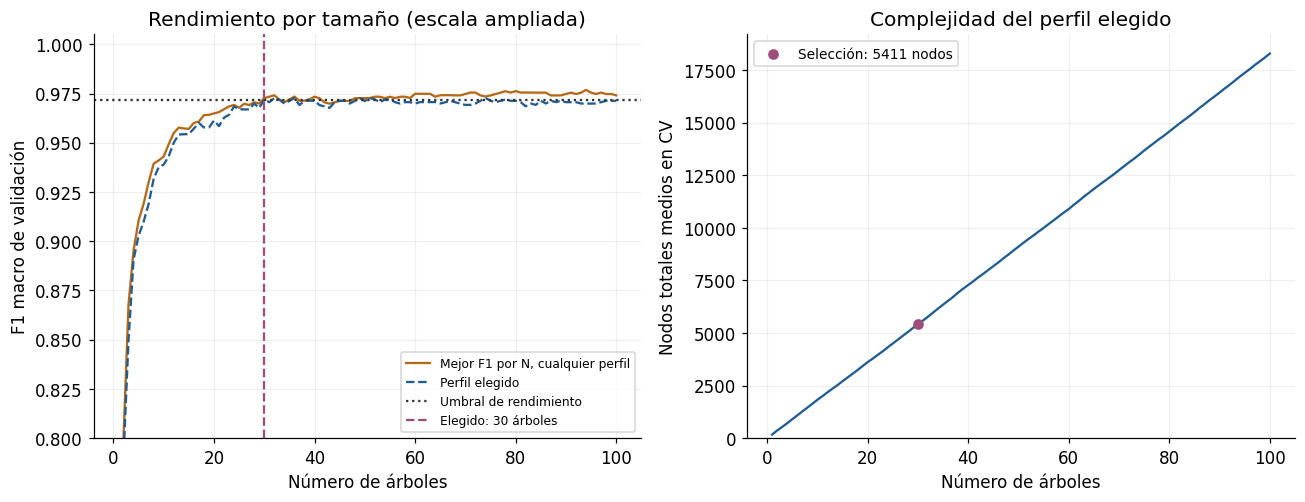

In [ ]:
curva = resumen[resumen.perfil_id == int(elegido.perfil_id)].sort_values('n_estimators')
frontera = resumen.groupby('n_estimators')['val_f1_macro'].max()
fig, axes = plt.subplots(1,2,figsize=(12,4.7))
axes[0].plot(frontera.index,frontera.values,color=OCRE,label='Mejor F1 por N, cualquier perfil')
axes[0].plot(curva.n_estimators,curva.val_f1_macro,color=AZUL,label='Perfil elegido',linestyle='--')
axes[0].axhline(umbral_f1,color='#333333',linestyle=':',label='Umbral de rendimiento')
axes[0].axvline(N_ELEGIDO,color=ROSA,linestyle='--',label=f'Elegido: {N_ELEGIDO} árboles')
axes[0].set(xlabel='Número de árboles',ylabel='F1 macro de validación',
            title='Rendimiento por tamaño (escala ampliada)',ylim=(0.80,1.005))
axes[0].legend(fontsize=8,loc='lower right')
axes[1].plot(curva.n_estimators,curva.nodos_totales,color=AZUL)
axes[1].scatter([N_ELEGIDO],[elegido.nodos_totales],color=ROSA,zorder=5,
                 label=f'Selección: {elegido.nodos_totales:.0f} nodos')
axes[1].set(xlabel='Número de árboles',ylabel='Nodos totales medios en CV',
            title='Complejidad del perfil elegido',ylim=(0,None))
axes[1].legend(fontsize=9)
for ax in axes:ax.grid(alpha=.2)
fig.tight_layout();plt.show()

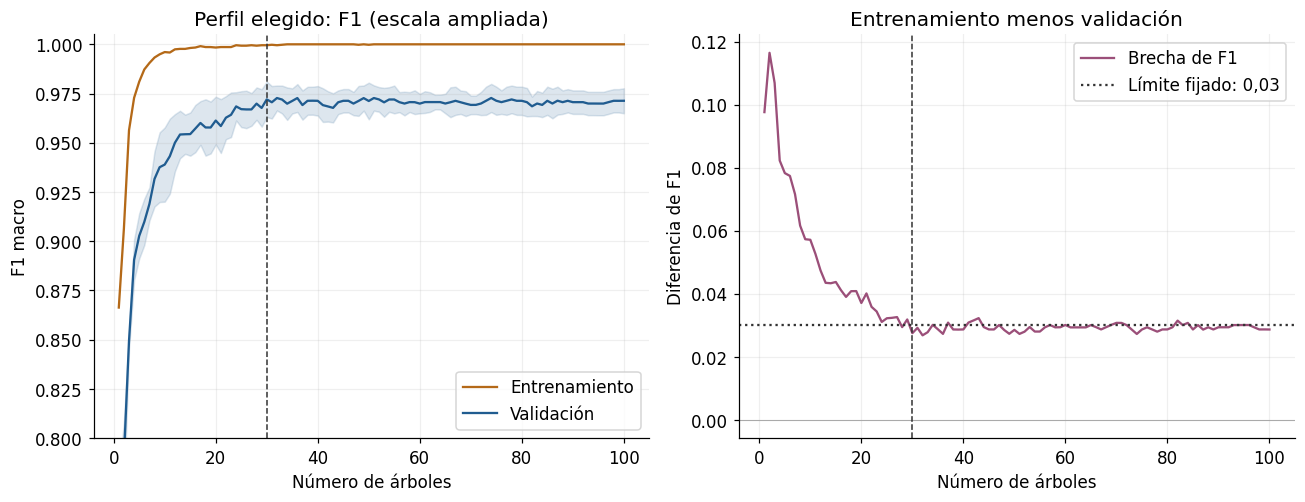

In [ ]:
fig,axes = plt.subplots(1,2,figsize=(12,4.7))
n = curva.n_estimators.to_numpy()
media = curva.val_f1_macro.to_numpy(); sd = curva.val_f1_std.to_numpy()
axes[0].plot(n,curva.train_f1_macro,color=OCRE,label='Entrenamiento')
axes[0].plot(n,media,color=AZUL,label='Validación')
axes[0].fill_between(n,np.clip(media-sd,0,1),np.clip(media+sd,0,1),color=AZUL,alpha=.15)
axes[0].set(title='Perfil elegido: F1 (escala ampliada)',xlabel='Número de árboles',
            ylabel='F1 macro',ylim=(.80,1.005))
axes[0].legend(loc='lower right')
axes[1].plot(n,curva.gap_f1,color=ROSA,label='Brecha de F1')
axes[1].axhline(BRECHA_MAXIMA,color='#333333',linestyle=':',label='Límite fijado: 0,03')
axes[1].axhline(0,color='#AAAAAA',linewidth=.7)
axes[1].set(title='Entrenamiento menos validación',xlabel='Número de árboles',ylabel='Diferencia de F1')
axes[1].legend()
for ax in axes:
    ax.axvline(N_ELEGIDO,color='#333333',linestyle='--',linewidth=1)
    ax.grid(alpha=.2)
fig.tight_layout();plt.show()

### 7.1. Lectura de los resultados de validación
Lo que sigue se arma con los números de esta corrida. Una curva casi plana no la vamos a leer como «ya es lo mismo» en sentido estadístico; solo describe lo que vimos con esta rejilla y esta semilla.


In [ ]:
reduccion_vs_max = 100*(1-elegido.nodos_totales/mejor_f1.nodos_totales)
display(Markdown(
    f'El mejor F1 de validación fue **{mejor_f1.val_f1_macro:.5f}**. '
    f'Nos quedamos con **{N_ELEGIDO} árboles** y un F1 de **{elegido.val_f1_macro:.5f}**: '
    f'solo **{100*(mejor_f1.val_f1_macro-elegido.val_f1_macro):.3f} puntos** por debajo del máximo. '
    f'La brecha de F1 quedó en **{100*elegido.gap_f1:.3f} puntos**, dentro del tope de 3. '
    f'Respecto al ganador estricto de F1, los nodos totales bajaron un **{reduccion_vs_max:.1f} %** '
    '(si saliera negativo, significaría que crecieron). '
    'Además, en toda la rejilla no apareció ningún candidato elegible con menos árboles.'))


El mejor F1 de validación fue **0.97685**. Nos quedamos con **30 árboles** y un F1 de **0.97204**: solo **0.481 puntos** por debajo del máximo. La brecha de F1 quedó en **2.750 puntos**, dentro del tope de 3. Respecto al ganador estricto de F1, los nodos totales bajaron un **79.0 %** (si saliera negativo, significaría que crecieron). Además, en toda la rejilla no apareció ningún candidato elegible con menos árboles.

## 8. Explicar y observar la poda
En el cuaderno del profesor sobre `ccp_alpha` queda clara la idea: el árbol primero crece y después se recortan subárboles cuya mejora de impureza no justifica lo que complican el modelo. Si subes `ccp_alpha`, hay más poda y el árbol queda más chico; si te pasas, aparece subajuste.

Aquí no elegimos alpha mirando la prueba ni armando la ruta de poda con las etiquetas del fold de validación. Para ver solo el efecto de la poda, dejamos fijos el número de árboles, `max_depth` y `min_samples_leaf` que ya elegimos, y comparamos únicamente los cuatro alphas de la rejilla con la misma validación que ya corrimos.

La poda puede reducir nodos sin mejorar el F1. El objetivo es un buen compromiso: no forzamos un alpha positivo si los datos no lo respaldan.


Quedó seleccionada poda posterior con ccp_alpha=0.001. Eso encaja con la idea del cuaderno del profesor: un alpha pequeño puede simplificar el árbol sin caer en subajuste.
Detención del crecimiento: {'max_depth': None, 'min_samples_leaf': 2}


,ccp_alpha,train_f1_macro,val_f1_macro,gap_f1,nodos_medios,hojas_medias,profundidad_media
2029,0.000,1.00000,0.96987,0.03013,220.45000,110.72500,11.93333
2129,0.001,0.99954,0.97204,0.02750,180.36667,90.68333,11.48333
2229,0.003,0.99490,0.96209,0.03281,124.01667,62.50833,10.25833
2329,0.006,0.97913,0.95032,0.02881,70.73333,35.86667,8.68333


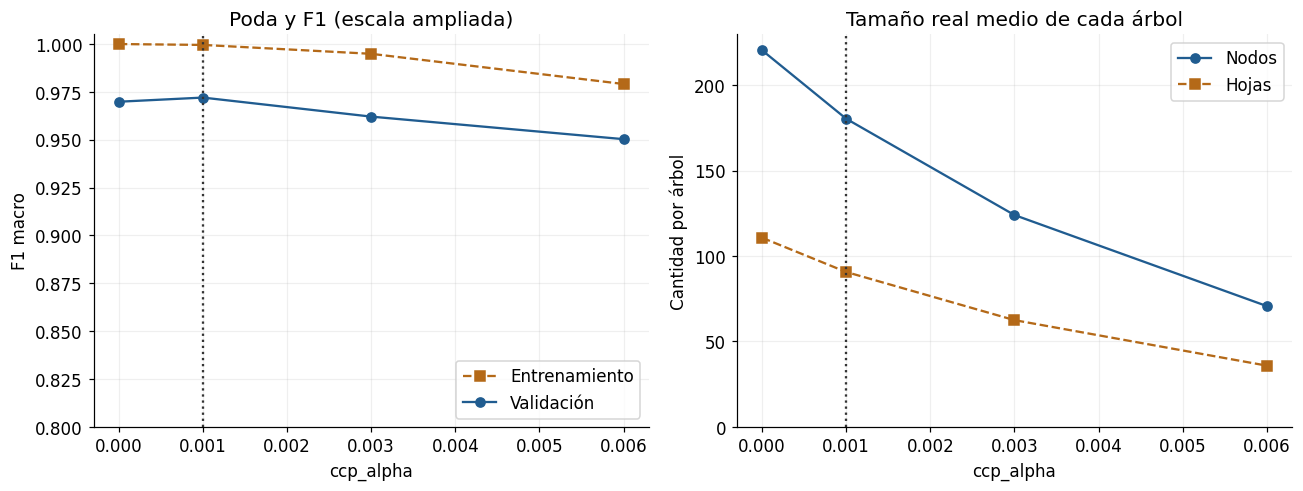

In [ ]:
ids_alpha = [i for i,p in enumerate(perfiles) if
    p['max_depth'] == PERFIL_ELEGIDO['max_depth'] and
    p['min_samples_leaf'] == PERFIL_ELEGIDO['min_samples_leaf']]
curva_alpha = resumen[(resumen.perfil_id.isin(ids_alpha)) &
                      (resumen.n_estimators == N_ELEGIDO)].copy()
curva_alpha['ccp_alpha'] = [perfiles[int(i)]['ccp_alpha'] for i in curva_alpha.perfil_id]
curva_alpha = curva_alpha.sort_values('ccp_alpha')
display(curva_alpha[['ccp_alpha','train_f1_macro','val_f1_macro','gap_f1',
                     'nodos_medios','hojas_medias','profundidad_media']])
fig,axes = plt.subplots(1,2,figsize=(12,4.6))
axes[0].plot(curva_alpha.ccp_alpha,curva_alpha.train_f1_macro,'s--',color=OCRE,label='Entrenamiento')
axes[0].plot(curva_alpha.ccp_alpha,curva_alpha.val_f1_macro,'o-',color=AZUL,label='Validación')
axes[0].set(title='Poda y F1 (escala ampliada)',xlabel='ccp_alpha',ylabel='F1 macro',ylim=(.80,1.005))
axes[0].legend()
axes[1].plot(curva_alpha.ccp_alpha,curva_alpha.nodos_medios,'o-',color=AZUL,label='Nodos')
axes[1].plot(curva_alpha.ccp_alpha,curva_alpha.hojas_medias,'s--',color=OCRE,label='Hojas')
axes[1].set(title='Tamaño real medio de cada árbol',xlabel='ccp_alpha',ylabel='Cantidad por árbol',ylim=(0,None))
axes[1].legend()
for ax in axes:
    ax.axvline(PERFIL_ELEGIDO['ccp_alpha'],color='#333333',linestyle=':')
    ax.grid(alpha=.2)
fig.tight_layout();plt.show()
if PERFIL_ELEGIDO['ccp_alpha'] > 0:
    explicacion_alpha = (f"Quedó seleccionada poda posterior con ccp_alpha={PERFIL_ELEGIDO['ccp_alpha']}. Eso encaja con la idea del cuaderno del profesor: un alpha pequeño puede simplificar el árbol sin caer en subajuste.")
else:
    explicacion_alpha = ('Probamos la poda, pero el mejor compromiso quedó con ccp_alpha=0. '
        'En ese caso no podemos decir que el bosque final quedó podado por costo-complejidad.')
print(explicacion_alpha)
print('Detención del crecimiento:',{k:PERFIL_ELEGIDO[k] for k in ['max_depth','min_samples_leaf']})


## 9. Ajustar el bosque final y evaluar el 20 % reservado
Congelamos los parámetros y entrenamos de nuevo con las **1.437 imágenes de entrenamiento**. No reciclamos el modelo de un fold. Además entrenamos una referencia de 100 árboles sin restricciones extras (`max_depth=None`, `min_samples_leaf=1`, `ccp_alpha=0`), solo para comparar rendimiento y complejidad. Esa referencia **no** entra en la elección final usando la prueba.

Predecimos una sola vez con cada bosque sobre las 360 imágenes reservadas. Después de ver esa comparación, no tocamos más los parámetros.


In [ ]:
modelo_final = crear_bosque(N_ELEGIDO,PERFIL_ELEGIDO).fit(X_train,y_train)
perfil_referencia = dict(max_depth=None,min_samples_leaf=1,ccp_alpha=0.0)
modelo_referencia = crear_bosque(MAX_ARBOLES,perfil_referencia).fit(X_train,y_train)
modelos = {'Seleccionado':modelo_final,'Referencia sin poda':modelo_referencia}
predicciones = {nombre:m.predict(X_test) for nombre,m in modelos.items()}

def tamano_bosque(modelo):
    nodos=np.array([t.tree_.node_count for t in modelo.estimators_])
    hojas=np.array([t.get_n_leaves() for t in modelo.estimators_])
    profundidades=np.array([t.get_depth() for t in modelo.estimators_])
    return dict(arboles=len(nodos),nodos_totales=int(nodos.sum()),nodos_medios=nodos.mean(),
                hojas_medias=hojas.mean(),profundidad_media=profundidades.mean(),
                profundidad_maxima=int(profundidades.max()))

prueba = pd.DataFrame({nombre:metricas_sklearn(y_test,p) for nombre,p in predicciones.items()}).T
prueba['Aciertos']=[int(np.sum(predicciones[n]==y_test)) for n in prueba.index]
prueba['Errores']=len(y_test)-prueba.Aciertos
complejidad = pd.DataFrame({n:tamano_bosque(m) for n,m in modelos.items()}).T
display(Markdown('**Rendimiento en la prueba reservada (n=360)**'));display(prueba)
display(Markdown('**Tamaño real después de reentrenar con todo el entrenamiento**'));display(complejidad)
assert len(modelo_final.estimators_) == N_ELEGIDO
assert np.allclose(prueba.accuracy,prueba.Aciertos/len(y_test))


**Rendimiento en la prueba reservada (n=360)**

,accuracy,precision_macro,recall_macro,f1_macro,Aciertos,Errores
Seleccionado,0.95278,0.95363,0.95230,0.95200,343,17
Referencia sin poda,0.96111,0.96197,0.96071,0.96072,346,14


**Tamaño real después de reentrenar con todo el entrenamiento**

,arboles,nodos_totales,nodos_medios,hojas_medias,profundidad_media,profundidad_maxima
Seleccionado,30.0,6648.0,221.60,111.30,12.06667,14.0
Referencia sin poda,100.0,34002.0,340.02,170.51,13.28000,16.0


### 9.1. Matriz de confusión y reporte por dígito
Las filas son la clase real y las columnas la clase predicha. La diagonal son los aciertos. El reporte trae precisión, recall, F1 y cuántos ejemplos hay por clase, más los promedios macro y ponderados. Todo esto es solo del bosque seleccionado.


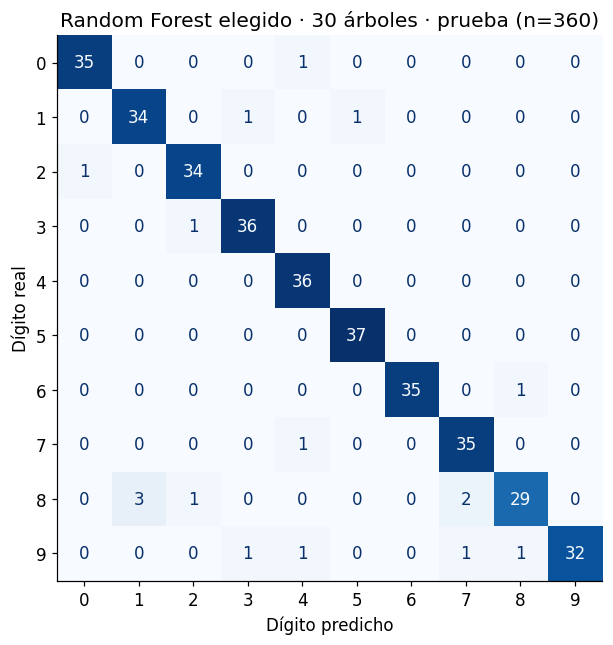

,precision,recall,f1-score,support
0,0.9722,0.9722,0.9722,36.0
1,0.9189,0.9444,0.9315,36.0
2,0.9444,0.9714,0.9577,35.0
3,0.9474,0.9730,0.9600,37.0
4,0.9231,1.0000,0.9600,36.0
5,0.9737,1.0000,0.9867,37.0
6,1.0000,0.9722,0.9859,36.0
7,0.9211,0.9722,0.9459,36.0
8,0.9355,0.8286,0.8788,35.0
9,1.0000,0.8889,0.9412,36.0


In [ ]:
y_pred = predicciones['Seleccionado']
cm = confusion_matrix(y_test,y_pred,labels=CLASES)
assert cm.sum() == len(y_test) and np.trace(cm) == prueba.loc['Seleccionado','Aciertos']
fig,ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(cm,display_labels=CLASES).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
ax.set(title=f'Random Forest elegido: {N_ELEGIDO} árboles, prueba (n=360)',
       xlabel='Dígito predicho',ylabel='Dígito real')
fig.tight_layout();plt.show()
reporte = classification_report(y_test,y_pred,labels=CLASES,output_dict=True,zero_division=0)
reporte.pop('accuracy',None)
display(pd.DataFrame(reporte).T.round(4))


### 9.2. Imágenes que se clasificaron incorrectamente
Mostramos hasta diez errores, en el orden en que aparecen en la prueba. Sirven para mirar casos concretos y entender dónde se confunde el modelo. No los usamos para volver a ajustar nada.


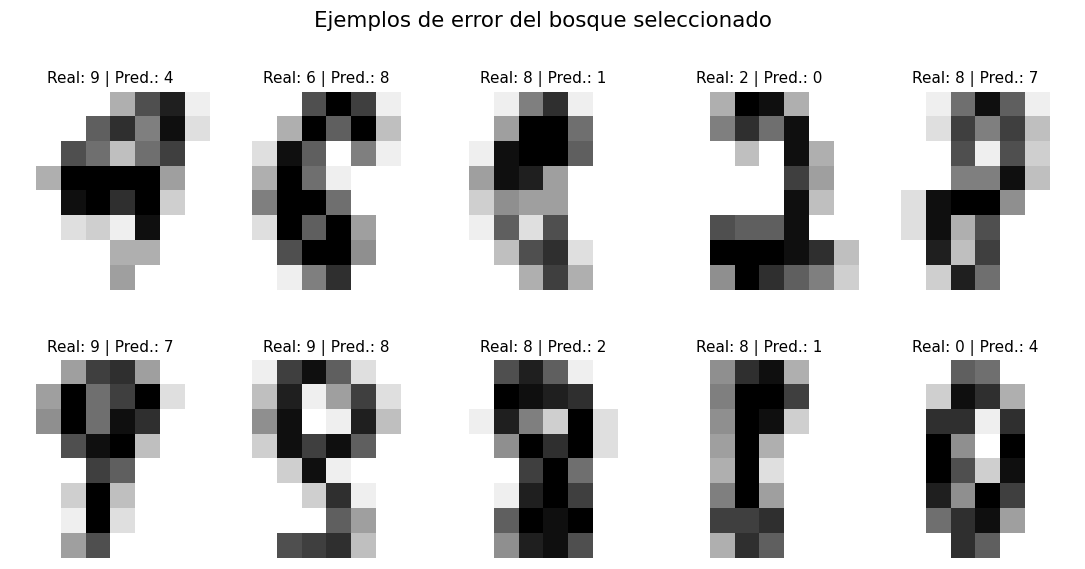

In [ ]:
errores = np.flatnonzero(y_test != y_pred)
if len(errores):
    fig,axes = plt.subplots(2,5,figsize=(10,5.6))
    for ax in axes.ravel():ax.axis('off')
    for ax,i in zip(axes.ravel(),errores[:10]):
        ax.imshow(X_test[i].reshape(8,8),cmap='gray_r',vmin=0,vmax=16)
        ax.set_title(f'Real: {y_test[i]} | Pred.: {y_pred[i]}',fontsize=10)
    fig.suptitle('Ejemplos de error del bosque seleccionado',fontsize=14)
    fig.tight_layout(h_pad=2.5);plt.show()
else:
    print('No hubo errores en esta partición de prueba.')

## 10. Qué significa «sin generar over-fitting» en este resultado
Con esta evaluación podemos ver si el desempeño se sostiene fuera del entrenamiento, pero no podemos demostrar que el sobreajuste desapareció por completo. Lo que sí hacemos es cuidar la fuga de información: la prueba no participa en la búsqueda. La brecha que usamos para elegir el modelo compara entrenamiento y validación de los mismos folds, no entrenamiento contra prueba.

El cuadro de abajo junta entrenamiento, validación y prueba del modelo elegido. Ojo con una sutileza: la fila de entrenamiento final usa un bosque reajustado con las 1.437 imágenes; las filas de CV se entrenaron con menos datos. No son exactamente el mismo modelo.


In [ ]:
metricas_train_final = metricas_sklearn(y_train,modelo_final.predict(X_train))
diagnostico = pd.DataFrame([
    {'Conjunto':'Entrenamiento (media folds)','F1 macro':elegido.train_f1_macro,'Exactitud':elegido.train_accuracy},
    {'Conjunto':'Validación (media folds)','F1 macro':elegido.val_f1_macro,'Exactitud':elegido.val_accuracy},
    {'Conjunto':'Entrenamiento (reajuste final)','F1 macro':metricas_train_final['f1_macro'],'Exactitud':metricas_train_final['accuracy']},
    {'Conjunto':'Prueba reservada','F1 macro':prueba.loc['Seleccionado','f1_macro'],'Exactitud':prueba.loc['Seleccionado','accuracy']}
])
display(diagnostico)
print(f'Brecha media CV: {100*elegido.gap_f1:.3f} puntos porcentuales de F1.')
print(f'Diferencia F1 validación menos prueba: '
      f'{100*(elegido.val_f1_macro-prueba.loc["Seleccionado","f1_macro"]):+.3f} puntos porcentuales.')
brecha_final = metricas_train_final['f1_macro']-prueba.loc['Seleccionado','f1_macro']
print(f'Brecha entrenamiento final menos prueba: {100*brecha_final:.3f} puntos de F1.')
display(Markdown(
    f'**Cómo leerlo:** la brecha final es de **{100*brecha_final:.2f} puntos de F1**. '
    'Eso supera los 3 puntos que usamos como guía en la validación cruzada, así que el buen '
    'comportamiento visto en CV no se traduce igual cuando comparamos entrenamiento final y prueba. '
    'Puede haber algo de sobreajuste residual, o simplemente variabilidad de esta partición; '
    'con un solo split no podemos separar esas dos cosas. '
    'No tocamos el modelo mirando la prueba: entregamos un compromiso entre simplicidad y '
    'rendimiento, no una prueba de que el sobreajuste desapareció.'))


Brecha media CV: 2.750 puntos porcentuales de F1.
Diferencia F1 validación menos prueba: +2.004 puntos porcentuales.
Brecha entrenamiento final menos prueba: 4.800 puntos de F1.


,Conjunto,F1 macro,Exactitud
0,Entrenamiento (media folds),0.99954,0.99954
1,Validación (media folds),0.97204,0.97216
2,Entrenamiento (reajuste final),1.00000,1.00000
3,Prueba reservada,0.95200,0.95278


**Cómo leerlo:** la brecha final es de **4.80 puntos de F1**. Eso supera los 3 puntos que usamos como guía en la validación cruzada, así que el buen comportamiento visto en CV no se traduce igual cuando comparamos entrenamiento final y prueba. Puede haber algo de sobreajuste residual, o simplemente variabilidad de esta partición; con un solo split no podemos separar esas dos cosas. No tocamos el modelo mirando la prueba: entregamos un compromiso entre simplicidad y rendimiento, no una prueba de que el sobreajuste desapareció.

## 11. Respuesta final al taller
Las conclusiones se arman con los resultados calculados: el tamaño real del bosque final y la estrategia de poda que de verdad quedó seleccionada.


In [ ]:
cf = complejidad.loc['Seleccionado']
cr = complejidad.loc['Referencia sin poda']
reduccion = 100*(1-cf.nodos_totales/cr.nodos_totales)
conclusiones = [
    f'**Datos y validación:** usamos {len(y_train)} imágenes para entrenar y {len(y_test)} para probar. La selección se hizo con cuatro folds estratificados.',
    f'**Cantidad mínima encontrada:** **{N_ELEGIDO} árboles**. Eso es el mínimo entre los tamaños de 1 a {MAX_ARBOLES} y los {len(perfiles)} perfiles, respetando la tolerancia de F1 y el tope de brecha.',
    f'**Configuración elegida:** max_depth={PERFIL_ELEGIDO["max_depth"]}, min_samples_leaf={PERFIL_ELEGIDO["min_samples_leaf"]}, ccp_alpha={PERFIL_ELEGIDO["ccp_alpha"]}. Además usamos gini, bootstrap y max_features="sqrt".',
    f'**Tamaño del bosque final:** {int(cf.nodos_totales)} nodos en total; en promedio {cf.nodos_medios:.1f} nodos y {cf.hojas_medias:.1f} hojas por árbol; profundidad media {cf.profundidad_media:.2f} y máxima {int(cf.profundidad_maxima)}.',
    f'**En validación cruzada:** F1 macro={elegido.val_f1_macro:.5f}, exactitud={elegido.val_accuracy:.5f} y brecha media de F1={elegido.gap_f1:.5f}.',
    f'**En la prueba reservada:** {int(prueba.loc["Seleccionado","Aciertos"])} de {len(y_test)} aciertos (exactitud **{prueba.loc["Seleccionado","accuracy"]:.2%}**). Precisión macro {prueba.loc["Seleccionado","precision_macro"]:.5f}, recall macro {prueba.loc["Seleccionado","recall_macro"]:.5f} y F1 macro **{prueba.loc["Seleccionado","f1_macro"]:.5f}**.',
    f'**Poda:** {explicacion_alpha} Los frenos de crecimiento que acompañan esa poda son los de la configuración elegida.',
    f'**Comparado con la referencia sin poda:** el bosque elegido usa un {reduccion:.1f}% menos de nodos totales. La referencia llegó a {prueba.loc["Referencia sin poda","accuracy"]:.2%} de exactitud en prueba; esa comparación es solo informativa y no sirvió para cambiar la selección.',
    f'**Sobreajuste:** en CV cumplimos el tope de brecha, pero entre el entrenamiento final y la prueba hay **{100*brecha_final:.2f} puntos de F1**. Eso es una separación notable fuera del entrenamiento: presentamos un buen compromiso, sin afirmar que el sobreajuste desapareció ni que las diferencias chicas sean estadísticamente significativas.'
]
display(Markdown('\n\n'.join(f'{i}. {texto}' for i,texto in enumerate(conclusiones,1))))


1. **Datos y validación:** usamos 1437 imágenes para entrenar y 360 para probar. La selección se hizo con cuatro folds estratificados.

2. **Cantidad mínima encontrada:** **30 árboles**. Eso es el mínimo entre los tamaños de 1 a 100 y los 24 perfiles, respetando la tolerancia de F1 y el tope de brecha.

3. **Configuración elegida:** max_depth=None, min_samples_leaf=2, ccp_alpha=0.001. Además usamos gini, bootstrap y max_features="sqrt".

4. **Tamaño del bosque final:** 6648 nodos en total; en promedio 221.6 nodos y 111.3 hojas por árbol; profundidad media 12.07 y máxima 14.

5. **En validación cruzada:** F1 macro=0.97204, exactitud=0.97216 y brecha media de F1=0.02750.

6. **En la prueba reservada:** 343 de 360 aciertos (exactitud **95.28%**). Precisión macro 0.95363, recall macro 0.95230 y F1 macro **0.95200**.

7. **Poda:** Quedó seleccionada poda posterior con ccp_alpha=0.001. Eso encaja con la idea del cuaderno del profesor: un alpha pequeño puede simplificar el árbol sin caer en subajuste. Los frenos de crecimiento que acompañan esa poda son los de la configuración elegida.

8. **Comparado con la referencia sin poda:** el bosque elegido usa un 80.4% menos de nodos totales. La referencia llegó a 96.11% de exactitud en prueba; esa comparación es solo informativa y no sirvió para cambiar la selección.

9. **Sobreajuste:** en CV cumplimos el tope de brecha, pero entre el entrenamiento final y la prueba hay **4.80 puntos de F1**. Eso es una separación notable fuera del entrenamiento: presentamos un buen compromiso, sin afirmar que el sobreajuste desapareció ni que las diferencias chicas sean estadísticamente significativas.

### Limitaciones y posibles extensiones
- El mínimo depende de la rejilla y de las tolerancias que fijamos. Otras profundidades, mínimos de hoja, alphas, más de 100 árboles u otra semilla podrían cambiar el compromiso.
- «Casi tan bueno como el mejor» no significa idéntico: aceptamos perder hasta 0,5 puntos de F1 a cambio de simplicidad. Por eso también mostramos el ganador estricto, para que esa decisión se pueda auditar.
- Con 2.400 comparaciones, el máximo de CV puede verse un poco optimista. Por eso dejamos la prueba aparte y la usamos solo al final.
- La división es aleatoria por imagen, no por escritor. No garantiza el mismo rendimiento con personas nuevas o con fotos externas.
- El número de nodos mide estructura, no exactamente memoria ni latencia.
- La brecha de tres puntos es una guía operativa, no una prueba estadística de «cero sobreajuste». Repetir el protocolo con otras semillas o con validación anidada ayudaría ver estabilidad; aquí no lo hicimos.


## 12. Verificaciones y resultados completos
Los DataFrames `resultados_folds` (9.600 filas) y `resumen` (2.400 filas) guardan todo en memoria. Abajo mostramos los diez mejores F1 y los mejores resultados posibles con menos árboles que la selección. Esa segunda tabla ayuda ver por qué esos candidatos más chicos no cumplen los dos criterios a la vez.


In [ ]:
assert len(resultados_folds) == len(perfiles)*MAX_ARBOLES*4
assert elegido.val_f1_macro >= umbral_f1-1e-12 and elegido.gap_f1 <= BRECHA_MAXIMA+1e-12
assert not resumen[(resumen.n_estimators < N_ELEGIDO) & resumen.elegible].shape[0]
assert np.isfinite(resumen.select_dtypes(include='number').to_numpy()).all()
assert np.all((resumen.val_f1_macro >= 0) & (resumen.val_f1_macro <= 1))
display(Markdown('**Los diez candidatos con mejor F1 medio de validación**'))
display(resumen.sort_values('val_f1_macro',ascending=False).head(10)[
    ['perfil_id','n_estimators','val_f1_macro','val_accuracy','gap_f1','nodos_medios','elegible']])
menores = resumen[resumen.n_estimators < N_ELEGIDO]
if len(menores):
    indices = menores.groupby('n_estimators').val_f1_macro.idxmax()
    display(Markdown('**Mejor F1 con menos árboles que el elegido (últimos diez tamaños)**'))
    display(menores.loc[indices].sort_values('n_estimators').tail(10)[
        ['n_estimators','val_f1_macro','gap_f1','elegible']])
print('Comprobaciones listas. La prueba no se usó para elegir parámetros.')
# Opcional: descomentar para exportar las tablas al entorno de Colab.
# resultados_folds.to_csv('RandomForest_resultados_folds.csv', index=False)
# resumen.to_csv('RandomForest_resumen_cv.csv', index=False)


Comprobaciones listas. La prueba no se usó para elegir parámetros.


**Los diez candidatos con mejor F1 medio de validación**

,perfil_id,n_estimators,val_f1_macro,val_accuracy,gap_f1,nodos_medios,elegible
893,8,94,0.97685,0.97704,0.02315,273.86170,True
979,9,80,0.97621,0.97634,0.02379,242.73750,True
977,9,78,0.97617,0.97634,0.02383,242.33333,True
980,9,81,0.97551,0.97565,0.02449,242.80247,True
981,9,82,0.97551,0.97565,0.02449,242.83537,True
982,9,83,0.97551,0.97565,0.02449,242.65663,True
971,9,72,0.97551,0.97565,0.02449,242.08333,True
970,9,71,0.97551,0.97565,0.02449,242.02817,True
996,9,97,0.97549,0.97565,0.02451,242.50000,True
894,8,95,0.97548,0.97565,0.02452,273.88421,True


**Mejor F1 con menos árboles que el elegido (últimos diez tamaños)**

,n_estimators,val_f1_macro,gap_f1,elegible
919,20,0.96492,0.03461,False
920,21,0.96558,0.03396,False
921,22,0.96704,0.03249,False
1222,23,0.96846,0.03107,False
1223,24,0.96921,0.03056,False
2024,25,0.96776,0.03224,False
2025,26,0.96982,0.02995,False
1226,27,0.96914,0.03086,False
1227,28,0.97057,0.02943,False
1328,29,0.96991,0.02962,False


## 13. Referencias y adaptación del repositorio
**Enunciado:** `_taller_08_Random_Forest.pdf`, página 1. También revisamos el cuaderno de `ccp_alpha` que el PDF enlaza.

**Repositorio de Eduardo Zurek:** commit `25c5f9dabb6d`. Cuadernos que miramos:

- [_007_001_Ejemplo_de_Árboles_de_Clasificación.ipynb](https://github.com/eduardozurek/ia/blob/25c5f9dabb6d0ca212a99cb780ad273c5cd37d06/_007_aprendizaje_supervisado/_007_arboles_de_decision/_007_001_Ejemplo_de_%C3%81rboles_de_Clasificaci%C3%B3n.ipynb).
- [_007_01_ccp_alpha_DecisionTreeClassifier.ipynb](https://github.com/eduardozurek/ia/blob/25c5f9dabb6d0ca212a99cb780ad273c5cd37d06/_007_aprendizaje_supervisado/_007_arboles_de_decision/_007_01_ccp_alpha_DecisionTreeClassifier.ipynb) (el del enunciado).
- [_007_02_Ejemplo_de_Random_Forest.ipynb](https://github.com/eduardozurek/ia/blob/25c5f9dabb6d0ca212a99cb780ad273c5cd37d06/_007_aprendizaje_supervisado/_007_arboles_de_decision/_007_02_Ejemplo_de_Random_Forest.ipynb).

Del ejemplo de Random Forest nos quedamos con la idea base (gini, bootstrap y selección aleatoria de atributos), pero cambiamos el dataset sintético por `digits`, aplicamos la división 80/20, validamos con cuatro folds y buscamos complejidad de forma explícita. Usamos `max_features='sqrt'` como forma actual de la configuración que en el ejemplo aparece como `auto`. La poda la estudiamos sobre los bosques; no copiamos un alpha ilustrativo del ejemplo como si fuera el óptimo.

**Documentación oficial consultada:**

- [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).
- [Poda por costo-complejidad](https://scikit-learn.org/stable/modules/tree.html#minimal-cost-complexity-pruning).

La búsqueda es propia de este taller. No hace falta `graphviz`, datasets externos ni volver a ejecutar los cuadernos originales.

## 14. Preparar la entrega
Completa los nombres de hasta tres integrantes, ejecuta todas las celdas en Colab y guarda el archivo con sus salidas. El PDF pide subir el cuaderno a un repositorio de GitHub compartido con `eduardozurek` y enviar el enlace por Brightspace. Este archivo no publica ni envía nada solo.
